# Подготовка данных и продолжение исследования

Используется очищенная таблица из `01_eda.ipynb`. Выполнены загрузка и групповое разбиение. Далее исследуются обучающие данные, выбираются признаки и схема предсказания CLASS/NSP. Подготовленные данные будут сохранены в конце для отдельного notebook обучения и подбора параметров.

## 1. Загрузка очищенной таблицы

Сначала необходимо выполнить ячейку сохранения в `01_eda.ipynb`. Загружаются все колонки; состав входов модели и разбиение ещё не определены.

In [1]:
import pandas as pd

from classifier.data.settings import DataSettings

settings = DataSettings()
cleaned_path = settings.raw_dir.parent / "prepared" / "ctg_cleaned.csv"
df = pd.read_csv(cleaned_path, parse_dates=["Date"])
print(f"Размер исходной таблицы: \n\t{df.shape[0]} строк\n\t{df.shape[1]} колонок")

with pd.option_context("display.max_columns", None):
    display(df.head())

Размер исходной таблицы: 
	2108 строк
	40 колонок


,FileName,Date,SegFile,b,e,LBE,LB,AC,FM,UC,ASTV,MSTV,ALTV,MLTV,DL,DS,DP,DR,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,A,B,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP
0,Variab10.txt,1996-12-01,CTG0001.txt,240.0,357.0,120.0,120.0,0.0,0.0,0.0,73.0,0.5,43.0,2.4,0.0,0.0,0.0,0.0,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,9.0,2.0
1,Fmcs_1.txt,1996-05-03,CTG0002.txt,5.0,632.0,132.0,132.0,4.0,0.0,4.0,17.0,2.1,0.0,10.4,2.0,0.0,0.0,0.0,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
2,Fmcs_1.txt,1996-05-03,CTG0003.txt,177.0,779.0,133.0,133.0,2.0,0.0,5.0,16.0,2.1,0.0,13.4,2.0,0.0,0.0,0.0,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
3,Fmcs_1.txt,1996-05-03,CTG0004.txt,411.0,1192.0,134.0,134.0,2.0,0.0,6.0,16.0,2.4,0.0,23.0,2.0,0.0,0.0,0.0,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
4,Fmcs_1.txt,1996-05-03,CTG0005.txt,533.0,1147.0,132.0,132.0,4.0,0.0,5.0,16.0,2.4,0.0,19.9,0.0,0.0,0.0,0.0,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0


In [2]:
class_mapping = {
    1: 'A',
    2: 'B',
    3: 'C',
    4: 'D',
    5: 'E',
    6: 'AD',
    7: 'DE',
    8: 'LD',
    9: 'FS',
    10: 'SUSP'
}

nsp_mapping = {
    1: "Normal",
    2: "Suspect",
    3: "Pathologic"
}
str_cols = ["FileName", "SegFile"]
date_cols = ["Date"]
timestamp_cols = ["b", "e"]
categorical_cols = ["CLASS", "NSP", "Tendency"]
target_cols = ["CLASS", "NSP"]
class_cols = list(class_mapping.values())
numeric_cols = df.drop(columns=[*categorical_cols, *timestamp_cols, *class_cols]).select_dtypes(include=["float64"]).columns
feature_cols = df.columns.drop([*str_cols, *date_cols, *timestamp_cols, *class_cols, *target_cols]).tolist()

## 2. Разбиение данных

Сегменты одного исследования могут пересекаться по времени и содержать похожие измерения. Если они попадут в разные части выборки, качество модели может оказаться завышенным. Поэтому все сегменты с одинаковым FileName остаются вместе. Проверяется качество на других исследованиях.

Данные делятся примерно на 60% train, 20% validation и 20% test. Train используется для обучения, validation — для выбора настроек, test — для итоговой оценки. Из-за разного размера групп точные доли и баланс классов могут отличаться от желаемых.

Используется StratifiedGroupKFold с пятью частями, группировкой по FileName, стратификацией по CLASS и seed=42. Первые три части объединяются в train, четвёртая становится validation, пятая — test. Номера частей фиксируются заранее и не подбираются по качеству моделей.

Для предсказания CLASS и NSP используется одно разбиение если получится разделить классы обеих target с близкими пропорциями классов между выборками.

In [3]:
from sklearn.model_selection import StratifiedGroupKFold

RANDOM_STATE = 42

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fold = pd.Series(index=df.index, dtype="Int64")
for fold_number, (_, fold_indices) in enumerate(splitter.split(df, y=df["CLASS"], groups=df["FileName"])):
    fold.iloc[fold_indices] = fold_number

train_df = df.loc[fold.isin([0, 1, 2])].copy()
validation_df = df.loc[fold.eq(3)].copy()
test_df = df.loc[fold.eq(4)].copy()

splits = {"train": train_df, "validation": validation_df, "test": test_df}

pd.DataFrame({
    name: {
        "Строки": len(part),
        "Доля строк, %": round(len(part) / len(df) * 100, 2),
        "Исследования": part["FileName"].nunique(),
    }
    for name, part in splits.items()
}).T

,Строки,"Доля строк, %",Исследования
train,1266.0,60.06,212.0
validation,421.0,19.97,71.0
test,421.0,19.97,69.0


In [4]:
# Проверка состава разбиения
for one_col in target_cols:
    counts = pd.DataFrame({name: part[one_col].value_counts() for name, part in splits.items()}).fillna(0).astype(int).sort_index()
    shares = counts.div(pd.Series({name: len(part) for name, part in splits.items()}), axis="columns").mul(100).round(2)
    print(one_col)
    display(pd.concat({"Количество": counts, "Доля, %": shares}, axis=1))
    assert counts.gt(0).all().all(), f"Не все категории {one_col} представлены в каждой выборке"

CLASS


Количество                 Доля, %                  
           train validation test   train validation   test
CLASS                                                     
1.0          229         76   75   18.09      18.05  17.81
2.0          345        114  115   27.25      27.08  27.32
3.0           29         11   10    2.29       2.61   2.38
4.0           48         17   16    3.79       4.04   3.80
5.0           43         14   14    3.40       3.33   3.33
6.0          200         66   66   15.80      15.68  15.68
7.0          150         50   50   11.85      11.88  11.88
8.0           64         21   22    5.06       4.99   5.23
9.0           41         13   14    3.24       3.09   3.33
10.0         117         39   39    9.24       9.26   9.26

NSP


Количество                 Доля, %                  
         train validation test   train validation   test
NSP                                                     
1.0        982        328  332   77.57      77.91  78.86
2.0        178         59   54   14.06      14.01  12.83
3.0        106         34   35    8.37       8.08   8.31

**Вывод.** 
- В train вошло 1266 строк (60,06%), в validation и test — по 421 (19,97%).
- Исследования между частями не пересекаются.
- Все категории CLASS и NSP представлены в каждой части; доли классов близки.

## 3. Баланс CLASS и NSP на train

In [5]:
import matplotlib.pyplot as plt

train_balance = {}

for one_target_col, names in [("CLASS", class_mapping), ("NSP", nsp_mapping)]:
    counts = train_df[one_target_col].value_counts().sort_index()
    report = pd.DataFrame({
        "Категория": counts.index.map(names),
        "Количество": counts,
        "Доля, %": counts.div(len(train_df)).mul(100).round(2),
    })
    report.index = report.index.astype(int)
    report.index.name = one_target_col
    train_balance[one_target_col] = report
    display(report)

,Категория,Количество,"Доля, %"
CLASS,,,
1,A,229,18.09
2,B,345,27.25
3,C,29,2.29
4,D,48,3.79
5,E,43,3.40
6,AD,200,15.80
7,DE,150,11.85
8,LD,64,5.06
9,FS,41,3.24


,Категория,Количество,"Доля, %"
NSP,,,
1,Normal,982,77.57
2,Suspect,178,14.06
3,Pathologic,106,8.37


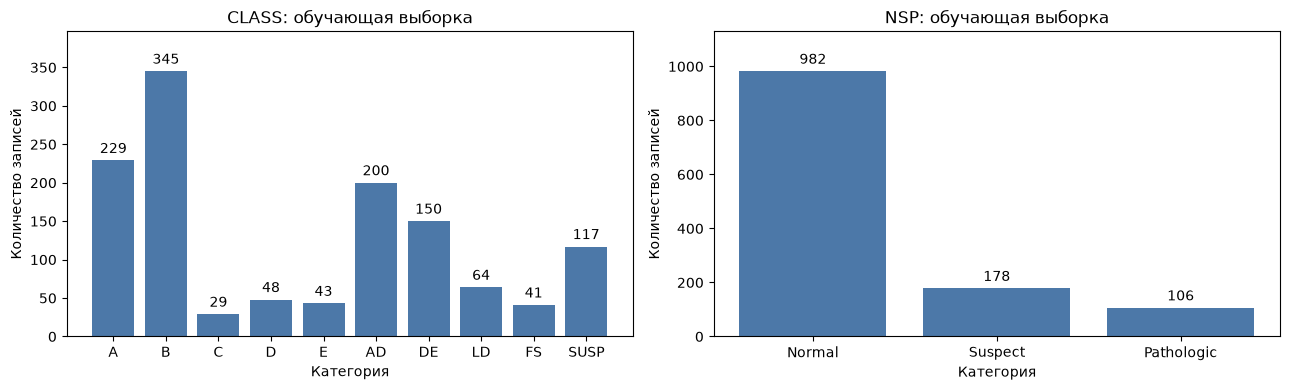

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, target in zip(axes, ["CLASS", "NSP"]):
    report = train_balance[target]
    bars = ax.bar(report["Категория"], report["Количество"], color="#4c78a8")
    ax.bar_label(bars, padding=3)
    ax.set_title(f"{target}: обучающая выборка")
    ax.set_xlabel("Категория")
    ax.set_ylabel("Количество записей")
    ax.set_ylim(0, report["Количество"].max() * 1.15)
fig.tight_layout()
plt.show()

**Вывод.**
- CLASS: самый частый паттерн B — 345 записей (27,25%), самый редкий C — 29 (2,29%). Разница почти в 12 раз; оценка качества для редких паттернов будет менее устойчивой.
- NSP: Normal — 982 записи (77,57%), Suspect — 178 (14,06%), Pathologic — 106 (8,37%). Модель, всегда выбирающая Normal, уже получит accuracy 77,57% на train, поэтому одной accuracy недостаточно.
- Для сравнения моделей используем macro-F1, который учитывает каждый класс с одинаковым весом, и precision/recall по классам. Для Pathologic отдельно оцениваем recall — какую долю патологических случаев модель находит, и precision — насколько часто её предупреждения верны.

## 4. Связь CLASS и NSP на train

### Таблица соответствия паттерна и состояния

Проверим, можно ли по известному CLASS однозначно определить NSP. Для этого посчитаем, сколько записей каждого паттерна относится к Normal, Suspect и Pathologic. Используется только train.

В таблице строки — паттерны, столбцы — категории NSP, числа — количество записей. Затем переведём количества в проценты внутри каждого паттерна и отобразим на heatmap.

Если в строке заполнен только один столбец, на train паттерну соответствует только один NSP. Если заполнены несколько — одного CLASS недостаточно для однозначного определения состояния.

NSP,Normal,Suspect,Pathologic
CLASS,,,
A,227,2,0
B,345,0,0
C,29,0,0
D,48,0,0
E,0,43,0
AD,198,2,0
DE,135,15,0
LD,0,0,64
FS,0,0,41


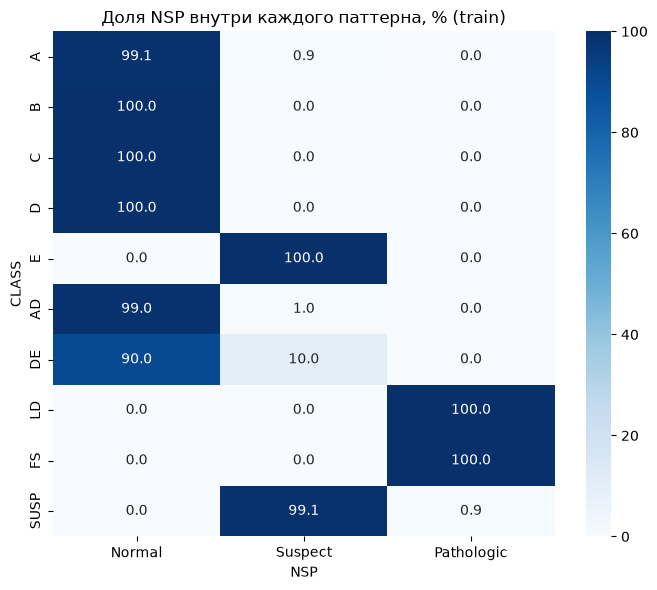

In [7]:
import seaborn as sns

class_nsp_counts = pd.crosstab(train_df["CLASS"], train_df["NSP"]).reindex(
    index=class_mapping, columns=nsp_mapping, fill_value=0
)
class_nsp_shares = class_nsp_counts.div(class_nsp_counts.sum(axis=1), axis=0).mul(100)
class_nsp_counts.index = class_nsp_counts.index.map(class_mapping)
class_nsp_counts.columns = class_nsp_counts.columns.map(nsp_mapping)
class_nsp_shares.index = class_nsp_counts.index
class_nsp_shares.columns = class_nsp_counts.columns

display(class_nsp_counts)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(class_nsp_shares, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, ax=ax)
ax.set_title("Доля NSP внутри каждого паттерна, % (train)")
ax.set_xlabel("NSP")
ax.set_ylabel("CLASS")
plt.tight_layout()
plt.show()

### Проверка неоднозначных соответствий

Для каждого паттерна определим число встречающихся категорий NSP, самую частую категорию и количество записей с другим NSP. 

In [8]:
class_nsp_summary = pd.DataFrame({
    "Записей": class_nsp_counts.sum(axis=1),
    "Количество категорий NSP": class_nsp_counts.gt(0).sum(axis=1),
    "Самый частый NSP": class_nsp_counts.idxmax(axis=1),
    "Доля самого частого NSP, %": class_nsp_shares.max(axis=1).round(2),
    "Записей с другим NSP": class_nsp_counts.sum(axis=1) - class_nsp_counts.max(axis=1),
})
display(class_nsp_summary)

# Примеры менее частого NSP внутри неоднозначных паттернов.
majority_nsp = pd.crosstab(train_df["CLASS"], train_df["NSP"]).idxmax(axis=1)
other_nsp = train_df["NSP"].ne(train_df["CLASS"].map(majority_nsp))
print("Записей с NSP, отличным от самого частого для паттерна:", other_nsp.sum())

,Записей,Количество категорий NSP,Самый частый NSP,"Доля самого частого NSP, %",Записей с другим NSP
CLASS,,,,,
A,229,2,Normal,99.13,2
B,345,1,Normal,100.00,0
C,29,1,Normal,100.00,0
D,48,1,Normal,100.00,0
E,43,1,Suspect,100.00,0
AD,200,2,Normal,99.00,2
DE,150,2,Normal,90.00,15
LD,64,1,Pathologic,100.00,0
FS,41,1,Pathologic,100.00,0


Записей с NSP, отличным от самого частого для паттерна: 20


**Вывод.**
- Связь CLASS и NSP сильная, но не однозначная: A, AD, DE и SUSP встречаются с двумя категориями NSP. У DE 15 из 150 записей относятся не к самой частой категории.
- Даже при известном истинном CLASS перевод в наиболее частый NSP не совпадает с разметкой у 20 из 1266 записей train (1,58%).
- Основной вариант — предсказывать CLASS и NSP непосредственно по измерениям. Для начала проще сравнить отдельные классификаторы для каждой цели; MLP с общими слоями и двумя выходами можно проверить как дополнительный эксперимент.
- Однозначность остальных паттернов установлена только на train. Test в этом исследовании не использовался.

## 5. Генерация признаков

### Длительность сегмента

Добавим во все три выборки (train, validation и test) признак `duration = e − b` — длительность сегмента. Количество событий и результат измерения может зависеть от продолжительности сегмента - стоит изучить возможные зависимости.

In [16]:
for part in splits.values():
    part["duration"] = part["e"] - part["b"]

## 6. Распределения и необычные значения на train

### Сводка исходных измерений

Проверим масштаб, разброс и частоту нулей в измерениях на train. Идентификаторы, дата, целевые колонки и индикаторы паттернов в сводку не включаются. Границы b/e и длительность duration включены для проверки их возможной роли. Tendency уже рассмотрен как категориальный признак. Столбцы исключаются только из этой сводки: исходные таблицы не изменяются.

`count` — число значений, `mean` — среднее, `std` — стандартное отклонение, `min/max` — границы. Квантили 25%, 50% и 75% показывают значения, ниже которых находится соответствующая доля наблюдений; 50% — медиана. Дополнительно считаются доля нулей, число уникальных значений и асимметрия. Положительная асимметрия указывает на хвост больших значений, отрицательная — малых.

IQR — разность между 75-м и 25-м процентилями. Границы для поиска необычных значений: `Q1 − 1,5 × IQR` и `Q3 + 1,5 × IQR`. Последний столбец показывает долю значений за ними. Это ориентир для исследования, а не правило удаления.

In [10]:
measurement_cols = [col for col in feature_cols if col not in categorical_cols] + ["b", "e", "duration"]
measurements = train_df[measurement_cols]
measurement_report = measurements.describe().T
measurement_report["Нули, %"] = measurements.eq(0).mean().mul(100)
measurement_report["Уникальных значений"] = measurements.nunique()
measurement_report["Асимметрия"] = measurements.skew()
iqr = measurement_report["75%"] - measurement_report["25%"]
lower = measurement_report["25%"] - 1.5 * iqr
upper = measurement_report["75%"] + 1.5 * iqr
outside_iqr = measurements.lt(lower) | measurements.gt(upper)
measurement_report["За границами IQR, %"] = outside_iqr.mean().mul(100)
display(measurement_report.round(2))

,count,mean,std,min,25%,50%,75%,max,"Нули, %",Уникальных значений,Асимметрия,"За границами IQR, %"
LBE,1266.0,133.19,10.28,106.0,126.00,133.0,141.00,160.0,0.00,47,0.04,0.00
LB,1266.0,133.19,10.28,106.0,126.00,133.0,141.00,160.0,0.00,47,0.04,0.00
AC,1266.0,2.59,3.24,0.0,0.00,1.0,4.00,21.0,43.05,20,1.42,2.21
FM,1266.0,9.71,46.31,0.0,0.00,0.0,3.00,564.0,59.00,82,7.83,13.43
UC,1266.0,3.55,2.84,0.0,1.00,3.0,5.00,23.0,15.48,18,0.93,0.55
ASTV,1266.0,47.39,17.22,13.0,32.00,50.0,62.00,87.0,0.00,74,-0.06,0.00
MSTV,1266.0,1.31,0.89,0.2,0.70,1.1,1.70,7.0,0.00,53,1.73,3.63
ALTV,1266.0,9.43,18.45,0.0,0.00,0.0,9.00,91.0,58.69,83,2.38,14.93
MLTV,1266.0,8.29,5.38,0.0,4.72,7.7,10.98,40.8,5.85,216,1.10,2.84
DL,1266.0,1.60,2.53,0.0,0.00,0.0,3.00,16.0,57.35,14,1.78,4.27


### Форма распределений: гистограммы

Для каждого измерения построим отдельную гистограмму. По горизонтали — значения признака, по вертикали — число записей в каждом интервале. 

Ищем скопление у нуля, длинные хвосты, несколько пиков и постоянные значения. Например, узкий пик около нуля и редкие столбцы справа означают, что большинство значений малы, но иногда встречаются большие. Шкалы у графиков разные: высоты и ширины столбцов между разными признаками напрямую не сравниваются. Цикл строит одинаковый график для каждой колонки; сетка нужна только для компактного размещения.

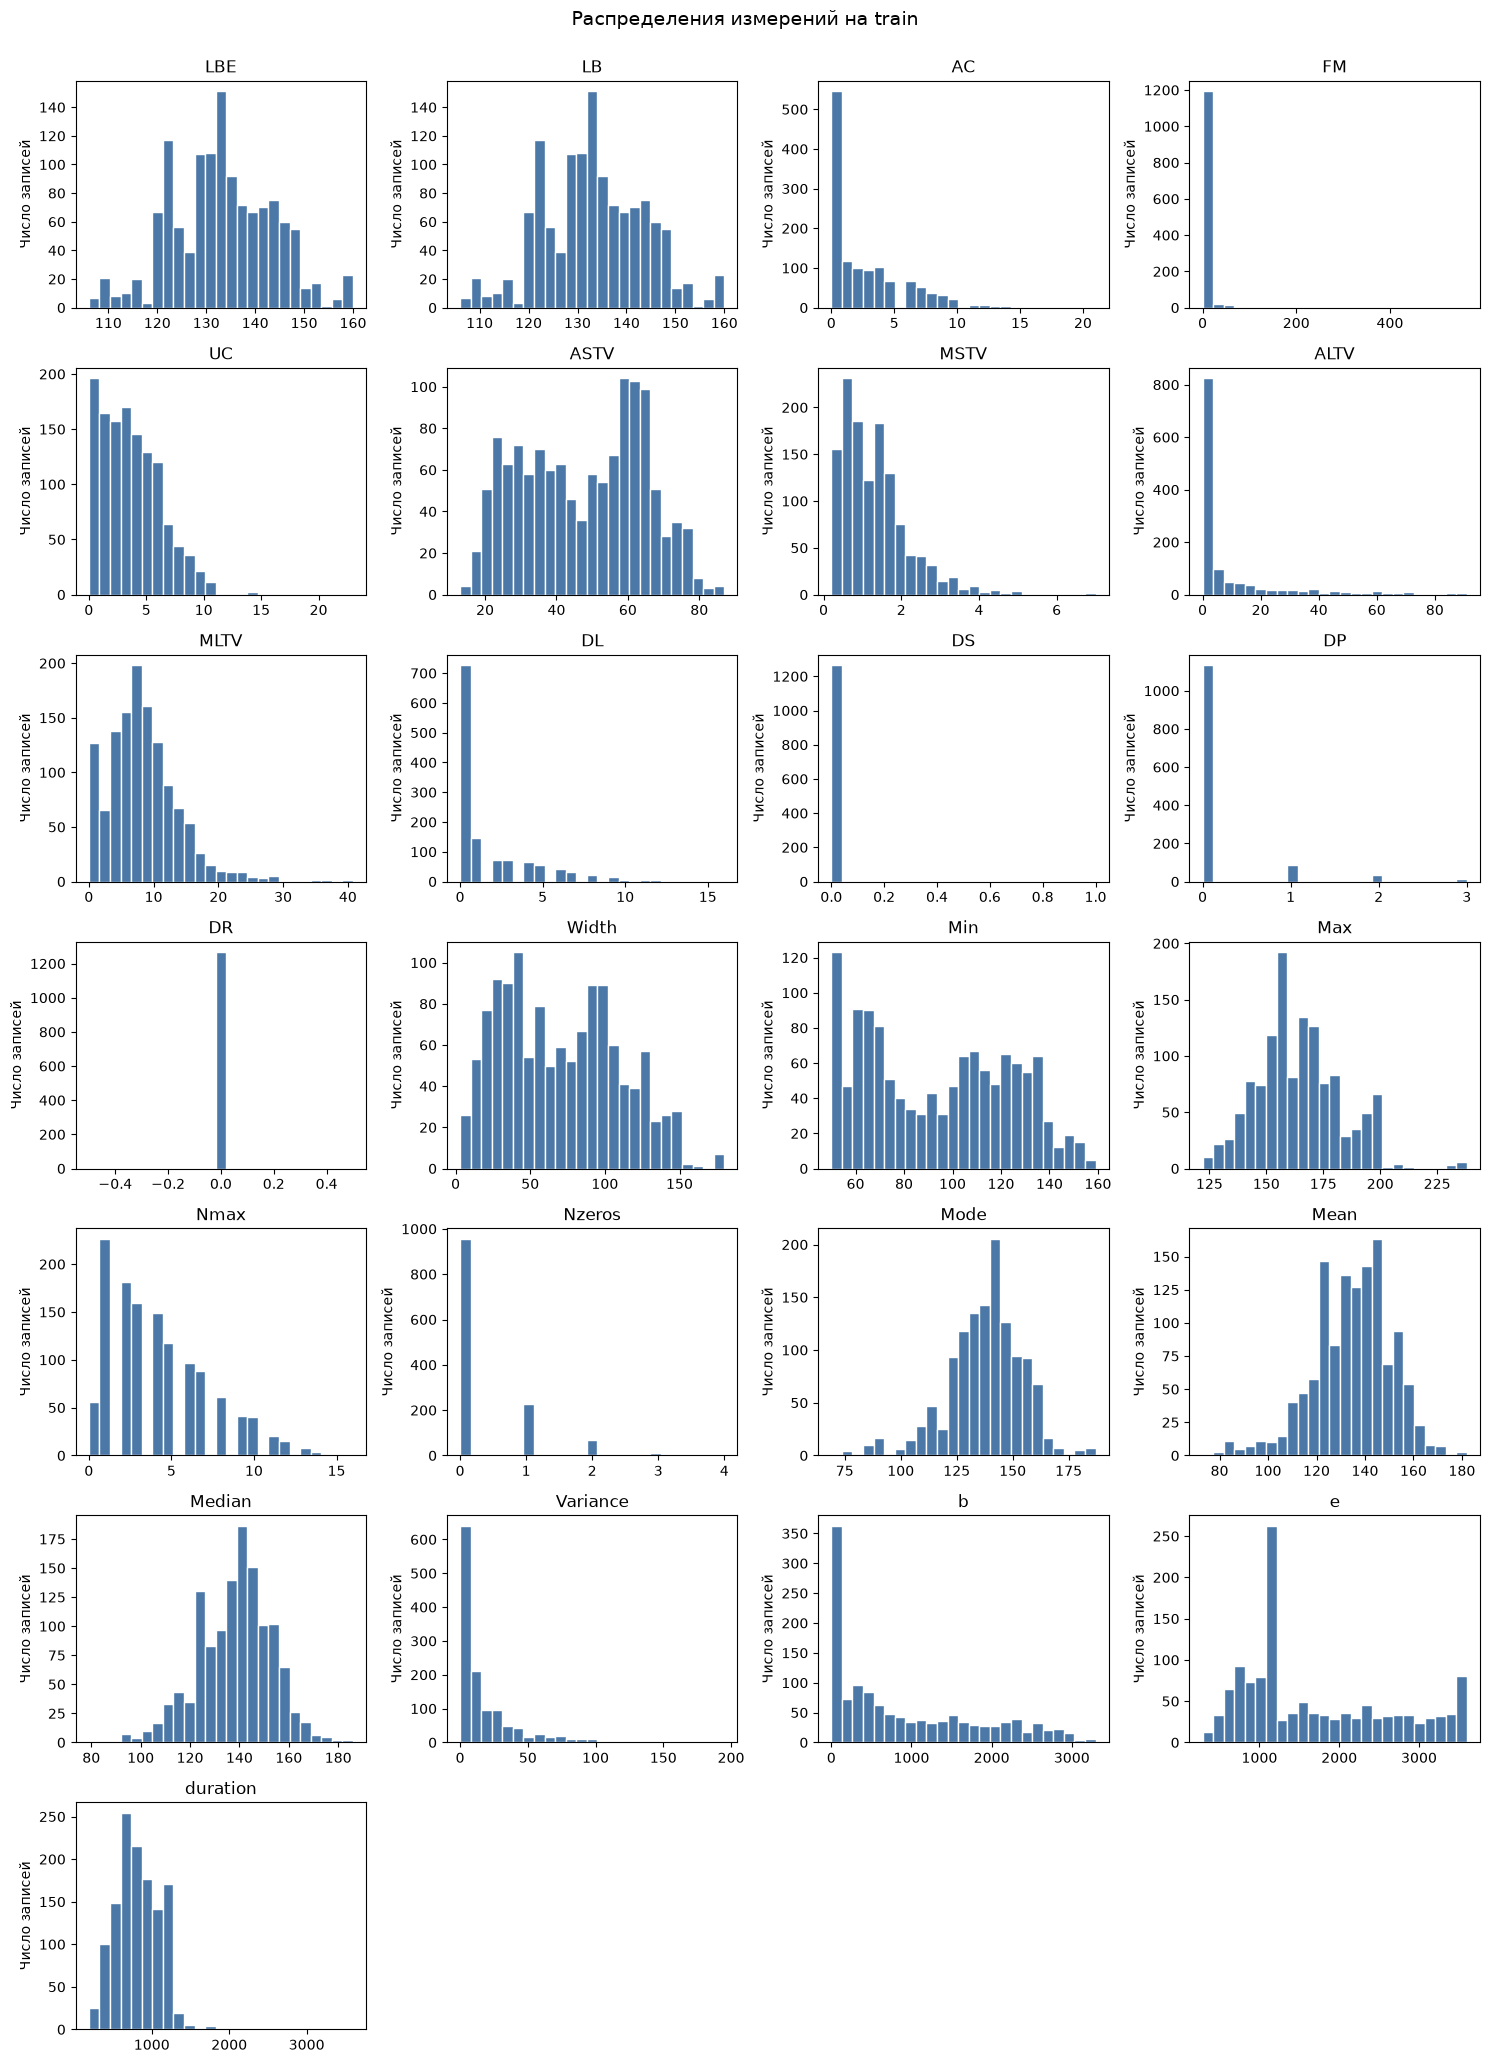

In [11]:
# Отдельные шкалы сохраняют читаемость признаков разного масштаба.
fig, axes = plt.subplots((len(measurement_cols) + 3) // 4, 4, figsize=(15, 21))
for ax, column in zip(axes.flat, measurement_cols):
    ax.hist(train_df[column], bins=25, color="#4c78a8", edgecolor="white")
    ax.set_title(column)
    ax.set_ylabel("Число записей")
for ax in axes.flat[len(measurement_cols):]:
    ax.set_visible(False)
fig.suptitle("Распределения измерений на train", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

### Разброс и крайние значения: boxplot

Для тех же измерений построим горизонтальные boxplot. Прямоугольник охватывает центральные 50% значений — от Q1 до Q3, линия внутри обозначает медиану. «Усы» доходят до крайних наблюдений в пределах границ `1,5 × IQR`, отдельные точки показывают значения за этими границами.

Смотрим, насколько широкий основной диапазон и с какой стороны находятся крайние значения. Точки не означают ошибку измерения. Если Q1 и Q3 равны нулю, прямоугольник сжимается в линию, а любое ненулевое значение становится отдельной точкой. Для редких событий это ожидаемо. 

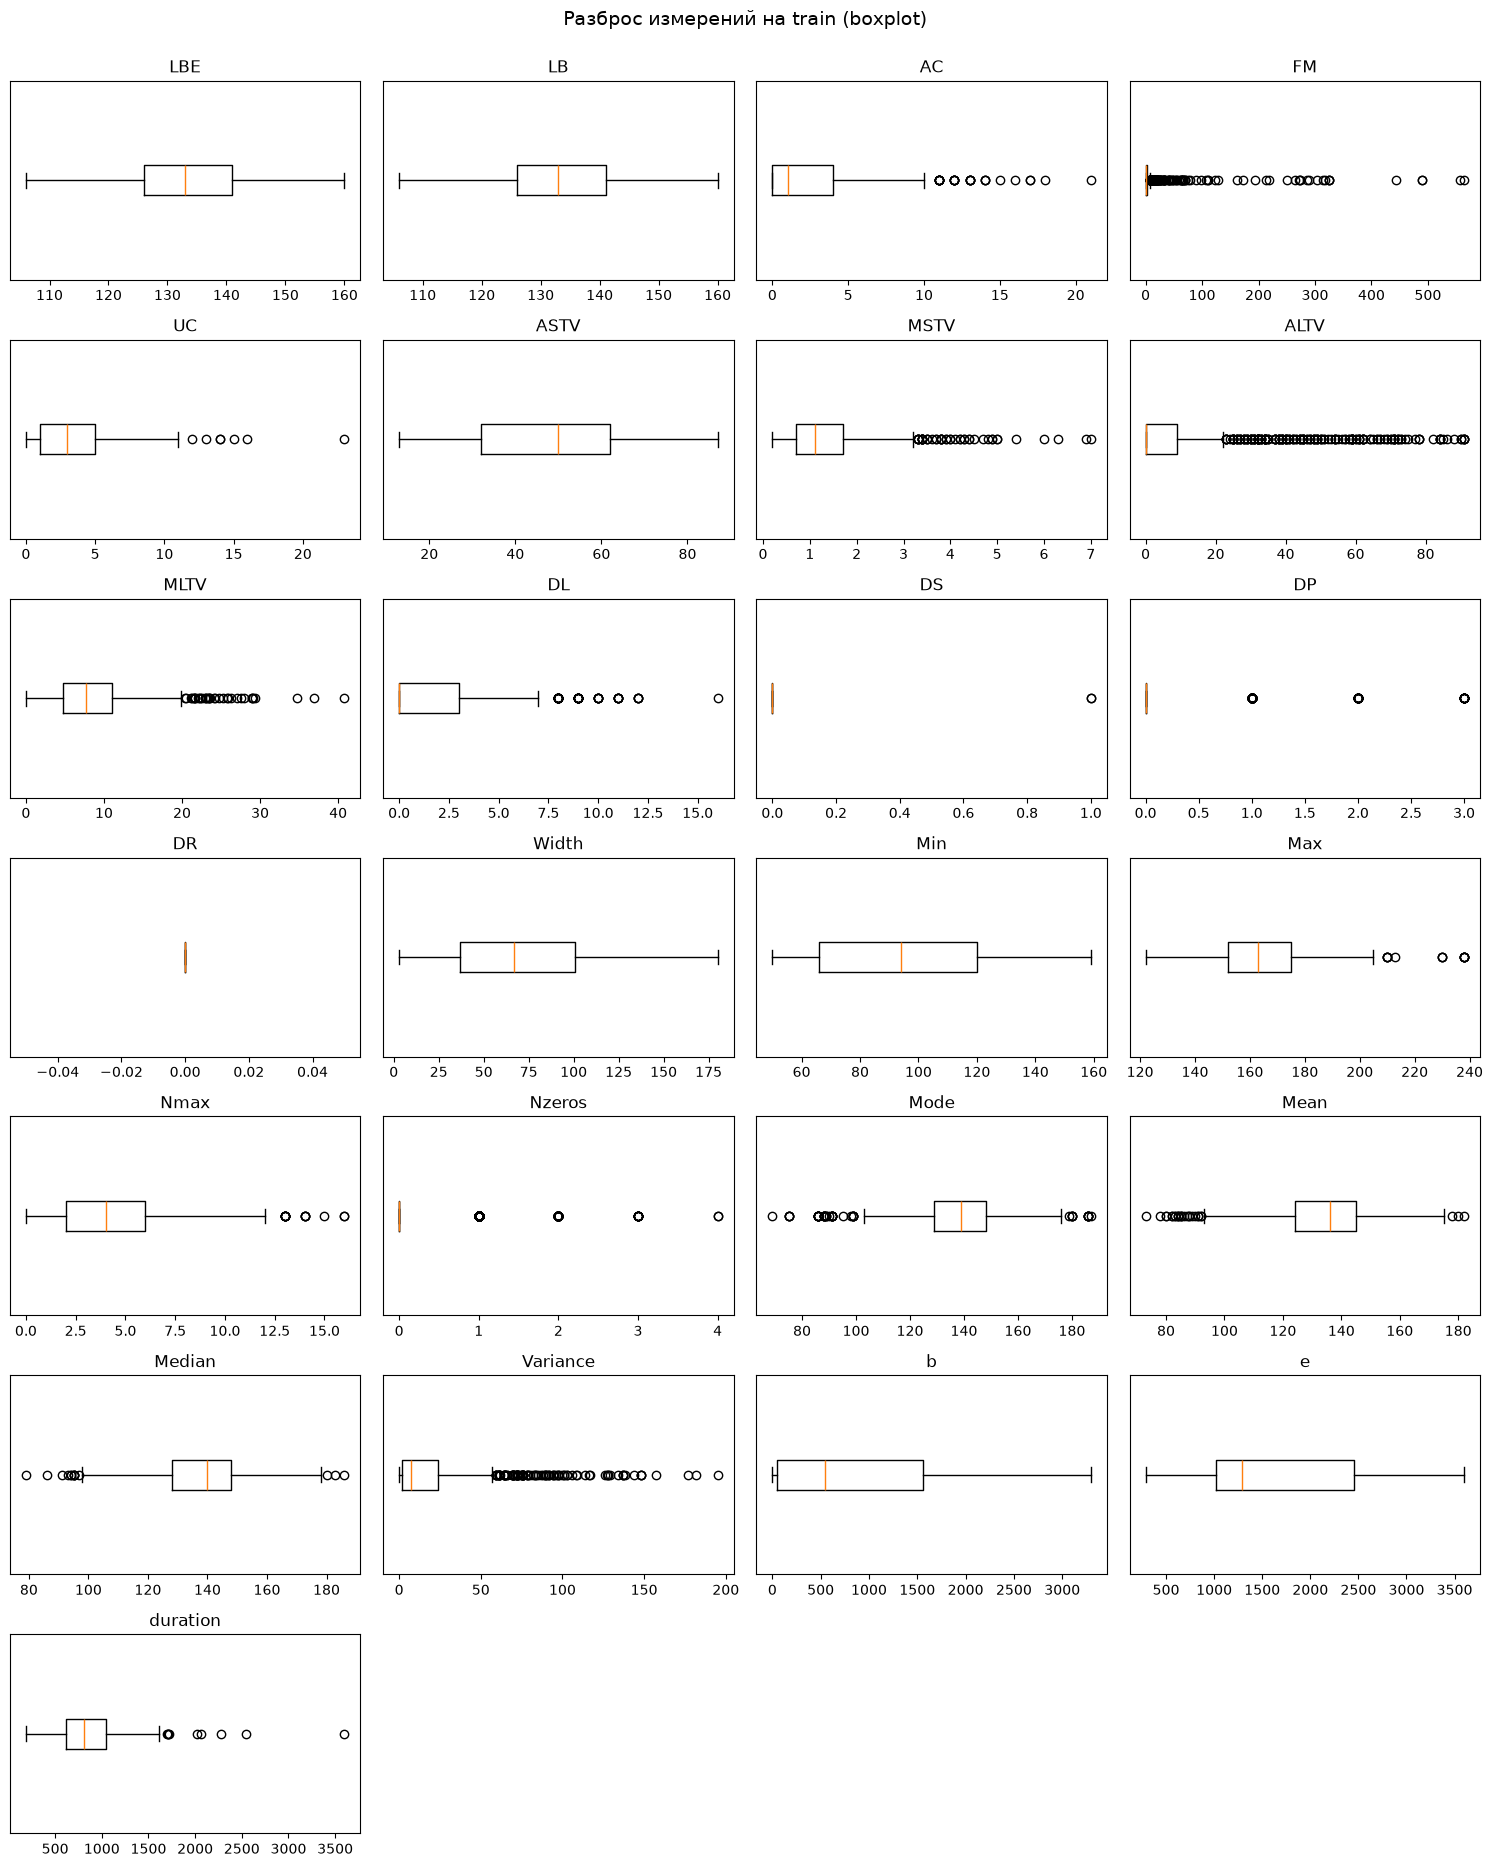

In [12]:
fig, axes = plt.subplots((len(measurement_cols) + 3) // 4, 4, figsize=(15, 19))
for ax, column in zip(axes.flat, measurement_cols):
    ax.boxplot(train_df[column], orientation="horizontal")
    ax.set_title(column)
    ax.set_yticks([])
for ax in axes.flat[len(measurement_cols):]:
    ax.set_visible(False)
fig.suptitle("Разброс измерений на train (boxplot)", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

**Вывод.**
- DR во всех записях train равен нулю — исключаем его.
- FM и ALTV равны нулю примерно в 59% записей и имеют длинные хвосты. У Variance также заметна правая асимметрия. Крайние значения сохраняем: оснований считать их ошибками нет.
- DS ненулевой только в двух записях. У DS, DP и Nzeros квартильные границы равны нулю, поэтому boxplot отмечает все ненулевые значения как выбросы. Эти признаки сохраняем.
- duration положителен во всех записях train: от 187 до 3599, медиана — 804,5.
- Масштабы признаков различаются. Для линейных моделей и MLP используем StandardScaler, обученный только на train.

## 7. Взаимосвязи признаков на train

### Совпадающие и связанные измерения

Проверим построчно, совпадают ли LBE и LB, а также равна ли ширина гистограммы разности её границ: Width = Max − Min. Совпадение сводных показателей ещё не означает равенства колонок, нужно сверить все значения. 

In [13]:
relationships = pd.DataFrame({
    "LBE − LB": train_df["LBE"] - train_df["LB"],
    "Width − (Max − Min)": train_df["Width"] - (train_df["Max"] - train_df["Min"]),
})
display(pd.DataFrame({
    "Совпадений": relationships.eq(0).sum(),
    "Всего строк": len(train_df),
    "Максимальная абсолютная разница": relationships.abs().max(),
}))

,Совпадений,Всего строк,Максимальная абсолютная разница
LBE − LB,1266,1266,0.0
Width − (Max − Min),1266,1266,0.0


Нулевая максимальная разница означает точное равенство на train. 

### Корреляции измерений

Посмотрим, какие измерения меняются вместе. Pearson отражает линейную связь, Spearman — связь порядков значений и помогает увидеть зависимости, которые не обязательно линейны. Значения близко к 1 означают совместный рост, близко к −1 — изменение в противоположных направлениях. Значение около нуля не исключает более сложной зависимости.

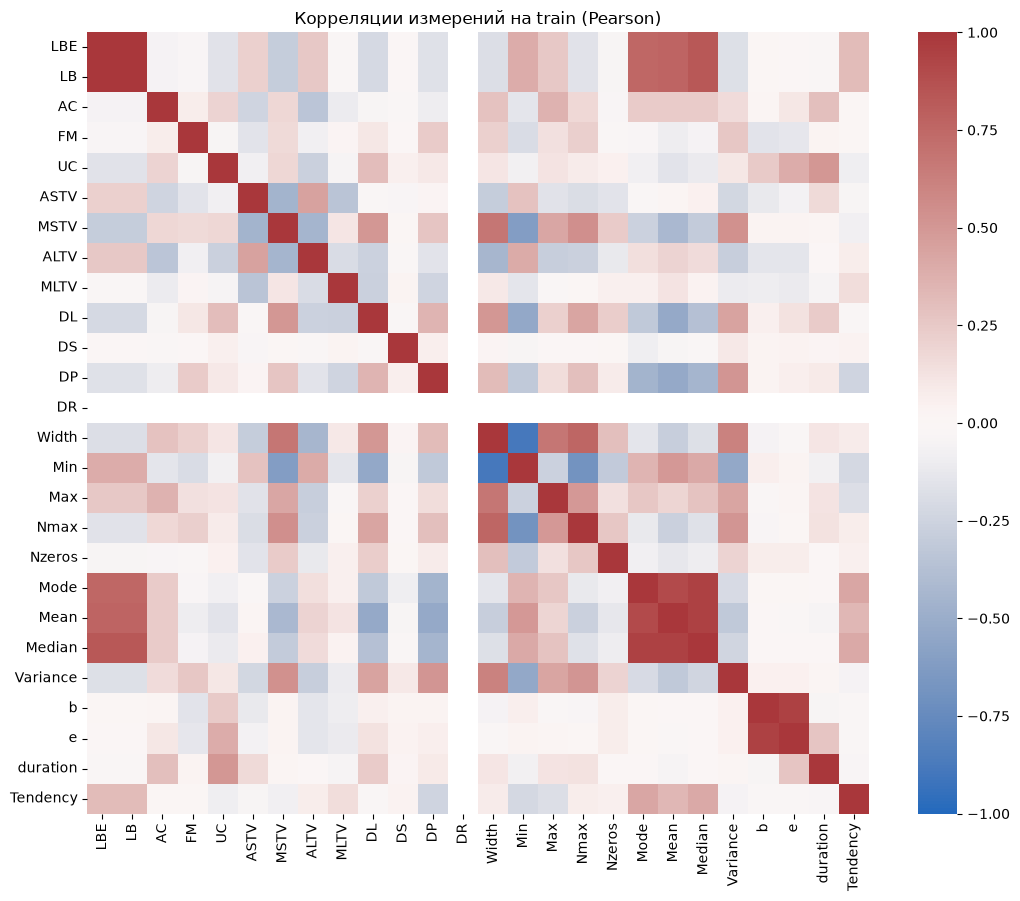

,Первый признак,Второй признак,Pearson,Spearman
0,LBE,LB,1.000,1.000
298,Mode,Median,0.951,0.965
319,b,e,0.950,0.853
304,Mean,Median,0.947,0.958
297,Mode,Mean,0.903,0.915
247,Width,Min,-0.889,-0.894
19,LBE,Median,0.836,0.873
43,LB,Median,0.836,0.873
18,LBE,Mean,0.770,0.822
42,LB,Mean,0.770,0.822


In [14]:
from itertools import combinations

categorical_feature_cols = [column for column in categorical_cols if column not in target_cols]
correlation_cols = [*measurement_cols, *categorical_feature_cols]
pearson = train_df[correlation_cols].corr(method="pearson")
spearman = train_df[correlation_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(pearson, cmap="vlag", vmin=-1, vmax=1, center=0, square=True, ax=ax)
ax.set_title("Корреляции измерений на train (Pearson)")
plt.tight_layout()
plt.show()

correlation_pairs = pd.DataFrame([
    {"Первый признак": first, "Второй признак": second,
     "Pearson": pearson.loc[first, second], "Spearman": spearman.loc[first, second]}
    for first, second in combinations(correlation_cols, 2)
])
strong_pairs = correlation_pairs.loc[correlation_pairs[["Pearson", "Spearman"]].abs().max(axis=1).ge(0.8)]
display(strong_pairs.sort_values("Pearson", key=lambda values: values.abs(), ascending=False).round(3))

- Для постоянных колонок корреляция не определена (NaN); на тепловой карте соответствующие клетки остаются пустыми (DR).
- CLASS, NSP и индикаторы паттернов в эту матрицу не входят.
- На тепловой карте показан Pearson, а в таблице — пары, для которых абсолютное значение хотя бы одной из двух корреляций не ниже 0,8. Это ориентир для проверки избыточности, не автоматическое правило удаления.

### Проверка временных характеристик

Сравним корреляции b, e и duration с количествами событий. Затем посмотрим распределения этих трёх характеристик по NSP: одинаковы ли они у разных категорий.

b и e задают положение сегмента внутри исходной записи, duration — время наблюдения. Между ними есть точная связь e = b + duration.

Pearson                                    Spearman                \
              AC     FM     UC     DL     DS     DP       AC     FM     UC   
b          0.017 -0.151  0.248  0.060  0.032  0.036    0.031 -0.306  0.277   
e          0.109 -0.134  0.396  0.131  0.040  0.064    0.156 -0.236  0.434   
duration   0.298  0.036  0.502  0.235  0.027  0.094    0.265  0.089  0.433   

                               
             DL     DS     DP  
b         0.102  0.037  0.036  
e         0.189  0.040  0.068  
duration  0.210  0.032  0.085

Корреляции временных характеристик:


,b,e,duration
b,1.000,0.950,-0.045
e,0.950,1.000,0.268
duration,-0.045,0.268,1.000


Медианы по NSP:


,b,e,duration
NSP,,,
Normal,703.5,1504.5,811.0
Suspect,262.5,1177.0,733.0
Pathologic,429.5,1241.0,794.0


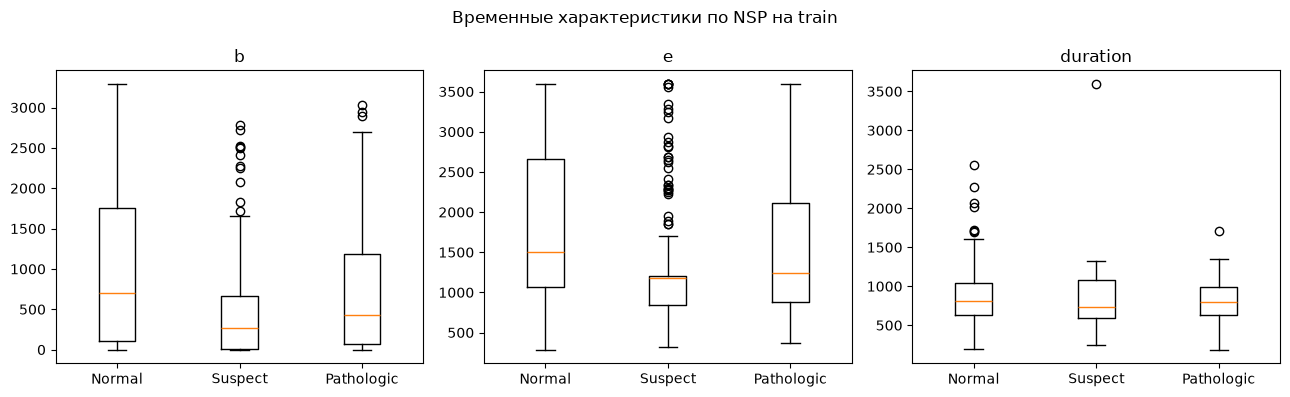

In [15]:
time_cols = ["b", "e", "duration"]
event_cols = ["AC", "FM", "UC", "DL", "DS", "DP"]
display(pd.concat({
    "Pearson": train_df[time_cols + event_cols].corr().loc[time_cols, event_cols],
    "Spearman": train_df[time_cols + event_cols].corr(method="spearman").loc[time_cols, event_cols],
}, axis=1).round(3))
print("Корреляции временных характеристик:")
display(train_df[time_cols].corr().round(3))
print("Медианы по NSP:")
display(train_df.groupby("NSP")[time_cols].median().rename(index=nsp_mapping))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, column in zip(axes, time_cols):
    ax.boxplot([train_df.loc[train_df["NSP"].eq(label), column] for label in nsp_mapping], tick_labels=list(nsp_mapping.values()))

    ax.set_title(column)
    ax.set_xlabel("")
fig.suptitle("Временные характеристики по NSP на train")
plt.tight_layout()
plt.show()

**Вывод по временным характеристикам.**
- b и e сильно связаны (Pearson 0,950), а duration с ними связан слабее: −0,045 и 0,268 соответственно.
- Из количеств событий наиболее заметно с duration связан UC (Pearson 0,502).
- Оставляем duration как характеристику времени наблюдения, b и e исключаем как координаты сегмента внутри записи. Их медианы различаются между NSP, поэтому это решение основано на смысле признаков, а не на отсутствии связи с целью.

**Вывод.**
- LBE и LB совпадают во всех 1266 строках train — исключаем LBE, оставляем LB.
- Width точно равен Max − Min — исключаем Width, оставляем Min и Max.
- Mode, Mean и Median сильно связаны (Pearson 0,90–0,95). Оставляем все три: они описывают разные характеристики гистограммы, а высокая корреляция сама по себе не означает полного дублирования.
- Для ASTV, MSTV, ALTV и MLTV абсолютные значения парных корреляций Pearson и Spearman ниже 0,8 — оставляем все четыре.
- Из временных характеристик оставляем duration; b и e исключаем.
- Tendency умеренно связан с Mode (Pearson 0,428; Spearman 0,380) и Median (0,410 и 0,365). Сильных корреляций по порогу 0,8 нет — оставляем признак: он описывает направление асимметрии гистограммы.
- Строка и столбец DR на heatmap пустые: признак постоянен, поэтому его корреляции равны NaN.

## 8. Выбор признаков и сохранение данных

### Выбранный набор признаков

- Убираем LBE: на train полностью совпадает с LB; оставляем автоматическое измерение LB.
- Убираем DR: на train постоянен.
- Убираем Width: точно восстанавливается как Max − Min; Min и Max сохраняем. Это убирает точную линейную зависимость.
- Вместо b и e оставляем duration = e − b: используем длительность наблюдения, исключаем координаты сегмента внутри записи. Количества событий сохраняем в исходном виде.
- Оставляем LB, AC, FM, UC, ASTV, MSTV, ALTV, MLTV, DL, DS, DP, Min, Max, Nmax, Nzeros, Mode, Mean, Median, Variance, Tendency и duration — 21 входной признак.
- Индикаторы A–SUSP и обе цели CLASS/NSP во входы не включаем. CLASS и NSP сохраняем как две отдельные цели.
- Date не используем. FileName и SegFile сохраняем только как служебные колонки: для групповой кросс-валидации и разбора ошибок; модель их не получает.

Редкие значения не удаляем. Одинаковый набор и преобразование применяем ко всем трём частям. Масштабирование сейчас не выполняем: в notebook обучения scaler будет обучаться на train и применяться к validation/test. CSV содержат исходный масштаб признаков.

In [16]:
model_feature_cols = [
    "LB", "AC", "FM", "UC", "ASTV", "MSTV", "ALTV", "MLTV",
    "DL", "DS", "DP", "Min", "Max", "Nmax", "Nzeros", "Mode",
    "Mean", "Median", "Variance", "Tendency", "duration",
]
metadata_cols = ["FileName", "SegFile"]
prepared_splits = {}
for name, part in splits.items():
    prepared = part.assign(duration=part["e"] - part["b"])
    prepared = prepared[metadata_cols + model_feature_cols + target_cols].copy()
    assert prepared["duration"].gt(0).all()
    assert not prepared.isna().any().any()
    assert prepared["SegFile"].is_unique
    prepared_splits[name] = prepared

for first, second in combinations(prepared_splits.values(), 2):
    assert set(first["FileName"]).isdisjoint(second["FileName"])
    assert set(first["SegFile"]).isdisjoint(second["SegFile"])
assert sum(map(len, prepared_splits.values())) == len(df)

prepared_dir = cleaned_path.parent
for name, prepared in prepared_splits.items():
    output_path = prepared_dir / f"{name}.csv"
    prepared.to_csv(output_path, index=False)
    restored = pd.read_csv(output_path)
    pd.testing.assert_frame_equal(prepared.reset_index(drop=True), restored, check_dtype=False)
    print(f"{name}: {len(prepared)} строк, {len(model_feature_cols)} признаков → {output_path.name}")

train: 1266 строк, 21 признаков → train.csv
validation: 421 строк, 21 признаков → validation.csv
test: 421 строк, 21 признаков → test.csv


**Итог.** Подготовлен общий набор из 21 входного признака для CLASS и NSP. В каждом файле дополнительно сохранены две цели и два служебных идентификатора. Train/validation/test не пересекаются по исходным исследованиям. Сохраненные файлы train.csv, validation.csv и test.csv будут использоваться для обучения моделей.